Simulation summary
t_end = 0.016666667 s
number of points = 1001

Opening instant
t_open = 0.007317546123 s

Quantities at t = 0-
v_source(0-)  = -927.569087461327 V
v_node(0-)    = -3.179401186770e-14 V
i_L(0-)       = -2.689950316348e-04 A
i_breaker(0-) = -3.179401186770e-13 A
v_breaker(0-) = 0.000000000000 V

Quantities at t = 0+
v_C(0+)       = -3.179401186770e-14 V
i_L(0+)       = -2.689950316348e-04 A

Initial derivatives at t = 0+
dv_C/dt(0+)   = -9.275690746028e+04 V/s
di_L/dt(0+)   = -9.275690874613e+05 A/s


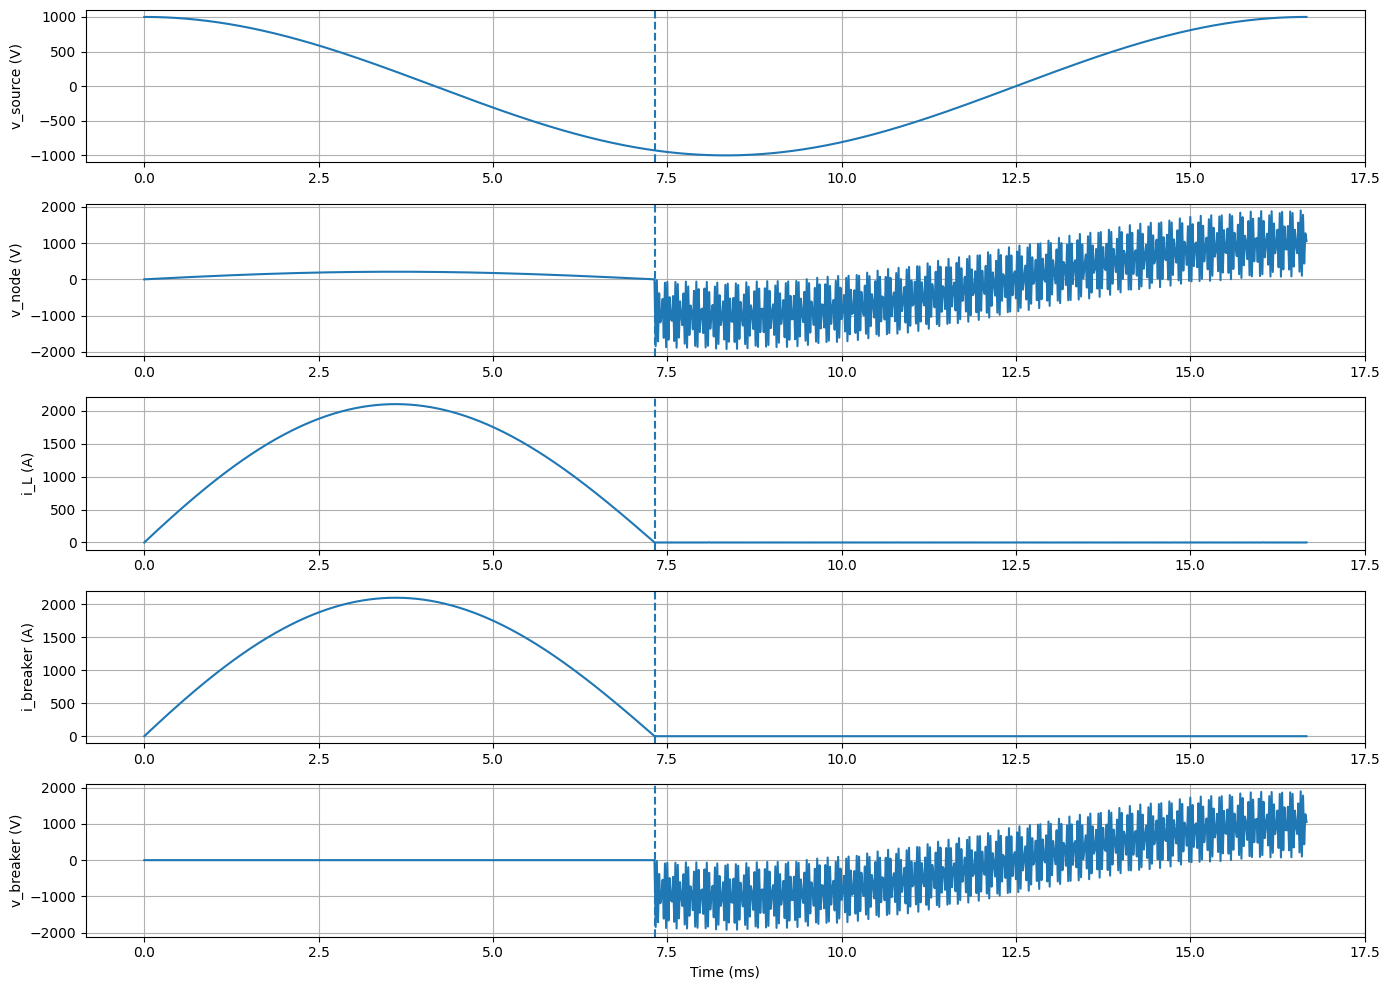

In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def source_voltage(time_s, v_peak, omega, phase_rad):
    """
    Return the source voltage waveform.
    """
    return v_peak * np.cos(omega * time_s + phase_rad)


def main():
    # Circuit parameters
    L_h = 1e-3
    C_f = 2.9e-9
    R_ohm = 0.1

    # Source parameters
    frequency_hz = 60.0
    omega = 2.0 * math.pi * frequency_hz
    v_peak = 1000.0
    phase_rad = 0.0

    # Simulation parameters
    n_cycles_total = 1
    points_per_cycle = 1000
    search_after_cycles = 0.4

    t_end_s = n_cycles_total / frequency_hz
    n_points = n_cycles_total * points_per_cycle + 1
    time_array_s = np.linspace(0.0, t_end_s, n_points)
    max_step_s = 1.0 / (frequency_hz * points_per_cycle)

    def rhs_closed(time_s, state):
        """
        Closed-breaker circuit:
        diL/dt = (vs - vC) / L
        dvC/dt = (iL - vC / R) / C
        """
        i_l_a = state[0]
        v_c_v = state[1]

        v_s_v = source_voltage(time_s, v_peak, omega, phase_rad)

        di_l_dt = (v_s_v - v_c_v) / L_h
        dv_c_dt = (i_l_a - v_c_v / R_ohm) / C_f

        return [di_l_dt, dv_c_dt]

    def rhs_open(time_s, state):
        """
        Open-breaker circuit:
        diL/dt = (vs - vC) / L
        dvC/dt = iL / C
        """
        i_l_a = state[0]
        v_c_v = state[1]

        v_s_v = source_voltage(time_s, v_peak, omega, phase_rad)

        di_l_dt = (v_s_v - v_c_v) / L_h
        dv_c_dt = i_l_a / C_f

        return [di_l_dt, dv_c_dt]

    def breaker_current_zero_event(time_s, state):
        """
        Event used to detect the first breaker-current zero after a small delay.
        Breaker current = vC / R while breaker is closed.
        """
        if time_s < search_after_cycles / frequency_hz:
            return 1.0

        v_c_v = state[1]
        i_breaker_a = v_c_v / R_ohm
        return i_breaker_a

    breaker_current_zero_event.terminal = True
    breaker_current_zero_event.direction = 0

    # Initial conditions at t = 0
    initial_state = [0.0, 0.0]

    # Simulate with breaker closed until the first current zero
    sol_closed = solve_ivp(
        fun=rhs_closed,
        t_span=(0.0, t_end_s),
        y0=initial_state,
        method="BDF",
        events=breaker_current_zero_event,
        dense_output=True,
        max_step=max_step_s,
        rtol=1e-3,
        atol=1e-3
    )

    if len(sol_closed.t_events[0]) == 0:
        raise RuntimeError("No breaker-current zero crossing was found.")

    t_open_s = sol_closed.t_events[0][0]
    state_0_minus = sol_closed.sol(t_open_s)

    i_inductor_0_minus_a = state_0_minus[0]
    v_node_0_minus_v = state_0_minus[1]
    i_breaker_0_minus_a = v_node_0_minus_v / R_ohm
    v_breaker_0_minus_v = 0.0
    v_source_0_minus_v = source_voltage(t_open_s, v_peak, omega, phase_rad)

    # Conditions at 0+
    i_inductor_0_plus_a = i_inductor_0_minus_a
    v_capacitor_0_plus_v = v_node_0_minus_v

    # Simulate after opening
    sol_open = solve_ivp(
        fun=rhs_open,
        t_span=(t_open_s, t_end_s),
        y0=[i_inductor_0_plus_a, v_capacitor_0_plus_v],
        method="BDF",
        dense_output=True,
        max_step=max_step_s,
        rtol=1e-6,
        atol=1e-8
    )

    # Build full waveforms
    mask_pre = time_array_s <= t_open_s
    mask_post = time_array_s > t_open_s

    i_l_total_a = np.zeros_like(time_array_s)
    v_c_total_v = np.zeros_like(time_array_s)
    i_breaker_total_a = np.zeros_like(time_array_s)
    v_breaker_total_v = np.zeros_like(time_array_s)

    state_pre = sol_closed.sol(time_array_s[mask_pre])
    i_l_total_a[mask_pre] = state_pre[0]
    v_c_total_v[mask_pre] = state_pre[1]
    i_breaker_total_a[mask_pre] = v_c_total_v[mask_pre] / R_ohm
    v_breaker_total_v[mask_pre] = 0.0

    if np.any(mask_post):
        state_post = sol_open.sol(time_array_s[mask_post])
        i_l_total_a[mask_post] = state_post[0]
        v_c_total_v[mask_post] = state_post[1]
        i_breaker_total_a[mask_post] = 0.0
        v_breaker_total_v[mask_post] = v_c_total_v[mask_post]

    v_source_total_v = source_voltage(time_array_s, v_peak, omega, phase_rad)

    dv_capacitor_dt_0_plus_v_per_s = i_inductor_0_plus_a / C_f
    di_inductor_dt_0_plus_a_per_s = (v_source_0_minus_v - v_capacitor_0_plus_v) / L_h

    print("Simulation summary")
    print(f"t_end = {t_end_s:.9f} s")
    print(f"number of points = {len(time_array_s)}")
    print("")
    print("Opening instant")
    print(f"t_open = {t_open_s:.12f} s")
    print("")
    print("Quantities at t = 0-")
    print(f"v_source(0-)  = {v_source_0_minus_v:.12f} V")
    print(f"v_node(0-)    = {v_node_0_minus_v:.12e} V")
    print(f"i_L(0-)       = {i_inductor_0_minus_a:.12e} A")
    print(f"i_breaker(0-) = {i_breaker_0_minus_a:.12e} A")
    print(f"v_breaker(0-) = {v_breaker_0_minus_v:.12f} V")
    print("")
    print("Quantities at t = 0+")
    print(f"v_C(0+)       = {v_capacitor_0_plus_v:.12e} V")
    print(f"i_L(0+)       = {i_inductor_0_plus_a:.12e} A")
    print("")
    print("Initial derivatives at t = 0+")
    print(f"dv_C/dt(0+)   = {dv_capacitor_dt_0_plus_v_per_s:.12e} V/s")
    print(f"di_L/dt(0+)   = {di_inductor_dt_0_plus_a_per_s:.12e} A/s")

    time_ms = time_array_s * 1e3
    t_open_ms = t_open_s * 1e3

    plt.figure(figsize=(14, 10))

    plt.subplot(5, 1, 1)
    plt.plot(time_ms, v_source_total_v)
    plt.axvline(t_open_ms, linestyle="--")
    plt.ylabel("v_source (V)")
    plt.grid(True)

    plt.subplot(5, 1, 2)
    plt.plot(time_ms, v_c_total_v)
    plt.axvline(t_open_ms, linestyle="--")
    plt.ylabel("v_node (V)")
    plt.grid(True)

    plt.subplot(5, 1, 3)
    plt.plot(time_ms, i_l_total_a)
    plt.axvline(t_open_ms, linestyle="--")
    plt.ylabel("i_L (A)")
    plt.grid(True)

    plt.subplot(5, 1, 4)
    plt.plot(time_ms, i_breaker_total_a)
    plt.axvline(t_open_ms, linestyle="--")
    plt.ylabel("i_breaker (A)")
    plt.grid(True)

    plt.subplot(5, 1, 5)
    plt.plot(time_ms, v_breaker_total_v)
    plt.axvline(t_open_ms, linestyle="--")
    plt.ylabel("v_breaker (V)")
    plt.xlabel("Time (ms)")
    plt.grid(True)

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()